# Finding structurally similar regulated substances
This notebook demonstrates how to query a global inventory for substances that are structurally similar to a molecule of interest. This type of analysis is useful for identifying chemicals that may present comparable regulatory or hazard concerns, even when they are not explicitly listed on a high-concern list.

**Prerequisites**
- Download a copy of the [example global inventory](https://github.com/envris/global-inventory-compiler/tree/main/data) from the GIC repository.
- Prepare a DataFrame of PubChem-derived structures using the corresponding structure-generation example notebook.

## Step 1: Load the inventory and structural data
Create an Inventory instance and load the associated structure DataFrame. The DataFrame contains precomputed RDKit fingerprints needed for similarity searching.

In [ ]:
from gic import DataFrame, Inventory

# Load the inventory and the associated structural data.
inv = Inventory("input/global_inventory.jsonl")
df = DataFrame.from_jsonl("output/pubchem_structures.jsonl")

# Show the available list tags for use in the next step.
print(inv.get_list_data().values())

dict_values(['JP-ISHA', 'PH-PICCS', 'US-TSCA_5F', 'CA-DSL', 'CN-IECSC', 'AU-ICHEMS_S6', 'KR-KECL_T', 'JP-CSCL', 'US-TSCA_TP', 'EU-REACH_PR', 'US-TSCA_CDR', 'CL-HSIUN', 'EU-ARN', 'JP-PRTR_SDS', 'US-TSCA_R', 'AU-NPI', 'TH-HAS', 'KR-KECL_R', 'TR-CSI', 'EU-POPs', 'MY-EHS', 'JP-CSCL_CI', 'KR-KECL_PP', 'TR-CSI_SVHC', 'JP-CSCL_CII', 'EU-CoRAP', 'NZ-NZIoC', 'EU-REACH_SVHC', 'EU-REACH_R', 'TW-CSI', 'US-TSCA_12C', 'EU-SPIN', 'JP-CSCL_PAC', 'KR-KECL', 'EU-REACH_XIV', 'AU-AIIC', 'US-TSCA_T', 'AU-ICHEMS_S7', 'AU-ICHEMS_S5', 'JP-CSCL_M', 'EU-REACH_XVII', 'US-TSCA', 'KR-KECL_SSIC', 'KR-KECL_PR', 'EU-CLP_VI', 'US-TSCA_5E', 'US-TRI', 'CASCC', 'PubChem'])


## Step 2: Map the structural data to the inventory
The structural DataFrame is initially keyed by PubChem CID. Populating it with SIDs makes the downstream query independent of the identifier type used in the original source data.

In [ ]:
df = inv.fill(df, "sid")  # Data frame will be updated with SIDs from the inventory

## Step 3: Define the high-concern inventory scope
Before running the similarity search, define the set of regulatory lists that represent substances of high concern or restriction.

In [ ]:
high_concern = [
    "AU-ICHEMS_S6",
    "AU-ICHEMS_S7",
    "EU-POPs",
    "EU-REACH_SVHC",
    "EU-REACH_XIV",
    "EU-REACH_XVII",
    "JP-CSCL_CI",
    "JP-CSCL_CII",
    "KR-KECL_PP",
    "KR-KECL_PR",
    "KR-KECL_R",
    "KR-KECL_SSIC",
    "US-TSCA_12C",
    "US-TSCA_5F",
    "US-TSCA_R",
]

high_concern_sids = inv.get_by_list_tags("sid", high_concern)

print(f"Number of substances in inventory: {len(inv.get_sids())}")
print(f"Number of substances on a high concern list: {len(high_concern_sids)}")

Number of substances in inventory: 320220
Number of substances on a high concern list: 6338


## Step 4: Define the input structure
The example input used here is a methylated analogue of the known persistent organic pollutant UV-328. Convert the SMILES string to an RDKit molecule and fingerprint so that it can be compared against the inventory structures.

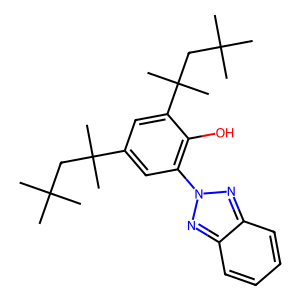

In [ ]:
from IPython.display import display
from rdkit import Chem
from rdkit.Chem import Draw

input_smiles = "OC=1C(=CC(=CC1C(C)(C)CC(C)(C)C)C(C)(C)CC(C)(C)C)N2N=C3C=CC=CC3=N2"
input_mol = Chem.MolFromSmiles(input_smiles)
input_fp = Chem.RDKFingerprint(input_mol)  # Required for similarity search

display(Draw.MolToImage(input_mol, size=(300, 300)))  # Display structure

## Step 5: Identify structurally similar substances
This step iterates over the structure DataFrame, calculates Tanimoto similarity to the input fingerprint, and records the SIDs associated with structures that meet the chosen cutoff.

In [ ]:
from rdkit import DataStructs

cutoff = 0.7

similar_sids = set()
for row in df:
    for fp in row.get_values("rdk_rdkfp"):
        similarity = DataStructs.TanimotoSimilarity(fp, input_fp)
        if similarity >= cutoff:
            similar_sids.update(row.get_values("sid"))

print(f"Number of substances in data frame: {len(df.get_values('sid'))}")
print(f"Number of substances similar to input structure: {len(similar_sids)}")

Number of substances in data frame: 140926
Number of substances similar to input structure: 33


## Step 6: Determine which similar substances are regulated
Python set operations provide an efficient way to identify which structurally similar substances are also present on the high-concern lists defined in Step 3.

In [ ]:
similar_sids_restricted = set(similar_sids) & set(high_concern_sids)
similar_sids_unrestricted = set(similar_sids) - set(high_concern_sids)

print(
    "Number of substances similar to input structure and restricted: "
    f"{len(similar_sids_restricted)}"
)
print(
    "Number of substance similar to input structure and not restricted: "
    f"{len(similar_sids_unrestricted)}"
)

Number of substance similar to input structure and restricted: 6
Number of substance similar to input structure and not restricted: 27


## Step 7: Export the results
SIDs are assigned during compilation and have limited meaning outside the context of a specific inventory. Export the matched records so they can be reviewed in spreadsheet form together with their identifiers and list tags.

In [ ]:
inv.export_as_data_frame(list(similar_sids_restricted)).to_xlsx(
    "output/similar_substances_restricted.xlsx"
)
inv.export_as_data_frame(list(similar_sids_unrestricted)).to_xlsx(
    "output/similar_substances_unrestricted.xlsx"
)